In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

#### Genarate Reproducible Non Linear Data

In [5]:
np.random.seed(42)

In [20]:
degrees = [1, 2, 10]

In [15]:
X = np.linspace(0, 10, 40).reshape(-1, 1)
# 0-10, 40 numbers, equally spaced between 0-10
?X

Type:        ndarray
String form:
[[ 0.        ]
           [ 0.25641026]
           [ 0.51282051]
           [ 0.76923077]
           [ 1.02564103]
           [ 1.28205128]
           [ 1.53 <...> 53846]
           [ 8.71794872]
           [ 8.97435897]
           [ 9.23076923]
           [ 9.48717949]
           [ 9.74358974]
           [10.        ]]
Length:      40
File:        c:\users\athre\appdata\local\programs\python\python310\lib\site-packages\numpy\__init__.py
Docstring:  
ndarray(shape, dtype=float, buffer=None, offset=0,
        strides=None, order=None)

An array object represents a multidimensional, homogeneous array
of fixed-size items.  An associated data-type object describes the
format of each element in the array (its byte-order, how many bytes it
occupies in memory, whether it is an integer, a floating point number,
or something else, etc.)

Arrays should be constructed using `array`, `zeros` or `empty` (refer
to the See Also section below).  The parameters given h

In [12]:
###### np.random.normal(0, 5, 40) - to genarate random noise
###### (Noise should be around the data)
###### Add Realistic Variation ot the output data
###### np.random.normal(mean, standard_variation, number_of_values)
y = 2 + 0.5 * X[:, 0] ** 2 + np.random.normal(0, 5, 40)
y

array([ 5.6923329 ,  2.88971452,  1.55325103,  0.79033951, -4.8666402 ,
       -0.7773933 ,  0.8802381 ,  8.89639351,  5.82197047, -4.15247888,
        6.90773083,  4.05223488,  3.34911781, 10.613937  , 13.59812713,
       14.0528503 ,  6.21942849,  9.95426685, 14.30720473, 18.74491827,
       12.75337273, 15.56874654, 12.37891027, 13.40884196, 24.99754035,
       29.32689377, 23.86217161, 30.98216153, 29.58069821, 26.42068657,
       33.39277684, 41.28124135, 35.48293424, 45.62203485, 26.9025894 ,
       46.37907202, 45.03878564, 45.50825056, 49.92757443, 42.06215543])

##### Divide the Data

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

In [28]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(28, 1)
(12, 1)
(28,)
(12,)


##### `include_bias = False` - is to tell the PolynomialFeatures not to create an additional constant column containing only 1's

In [33]:
for degree in degrees:
    model = make_pipeline(
    PolynomialFeatures(degree = degree, include_bias = False),
    LinearRegression()
    )
    model.fit(X_train, y_train)

    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)

    train_mse = mean_squared_error(y_train, train_prediction)
    test_mse = mean_squared_error(y_test, test_prediction)

    print(f"Polynomial Degree: {degree}")
    print(f"Training MSE: {train_mse:.2f}")
    print(f"Testing MSE: {test_mse:.2f}")
    print()

Polynomial Degree: 1
Training MSE: 35.51
Testing MSE: 27.68

Polynomial Degree: 2
Training MSE: 18.42
Testing MSE: 35.73

Polynomial Degree: 10
Training MSE: 15.22
Testing MSE: 30.97



##### Plotting Graph models

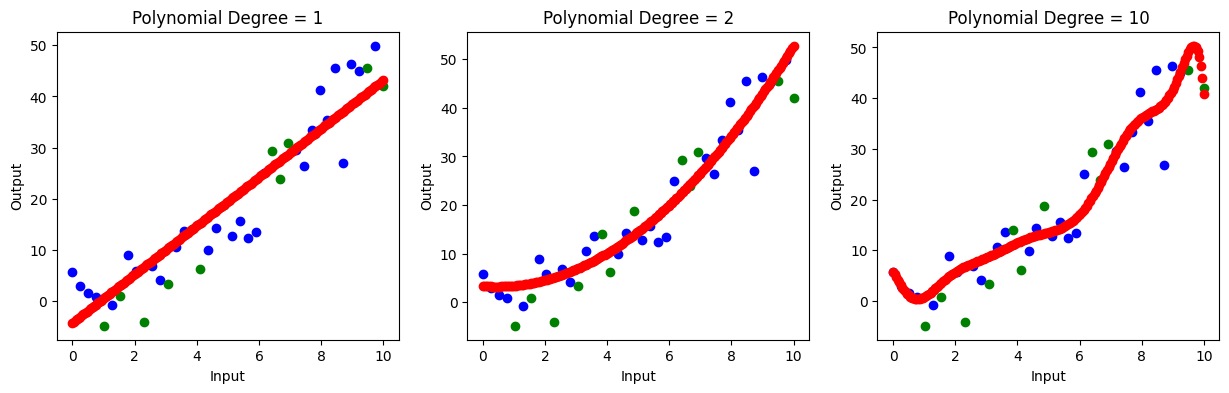

In [34]:
X_plot = np.linspace(0, 10, 200).reshape(-1, 1)

plt.figure(figsize = (15, 4))

for index, degree in enumerate(degrees):
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    model.fit(X_train, y_train)
    y_plot = model.predict(X_plot)

    plt.subplot(1, 3, index+1)
    plt.scatter(X_train, y_train, color = 'blue', label='Training Data')
    plt.scatter(X_test, y_test, color = 'green', label='Testing Data')
    plt.scatter(X_plot, y_plot, color = 'red', label='Prediction')

    plt.title(f"Polynomial Degree = {degree}")
    plt.xlabel("Input")
    plt.ylabel("Output")

#### Cross Validation and Model Selection

In [36]:
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

In [39]:
for degree in range(1, 11):
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )
    model.fit(X_train, y_train)
    
    scores = cross_val_score(
        model, X, y,
        cv=5, scoring='neg_mean_squared_error'

        # sckit-learn return the negative value of the mean swaured error (MSE) so that higher (less angative) values represent better model
    )
    mean_mse = - scores.mean()
    print(f'Degree: {degree}: CV MSE = {mean_mse:.2f}')

Degree: 1: CV MSE = 60.33
Degree: 2: CV MSE = 40.97
Degree: 3: CV MSE = 37.83
Degree: 4: CV MSE = 312.26
Degree: 5: CV MSE = 90.66
Degree: 6: CV MSE = 540.79
Degree: 7: CV MSE = 65875.62
Degree: 8: CV MSE = 299047.27
Degree: 9: CV MSE = 2549719.73
Degree: 10: CV MSE = 465557.39
